# Dry Bean Classification

13,611 dry beans photographed and measured — 16 shape features (area, perimeter, major/minor axis, eccentricity, solidity…) across 7 Turkish bean varieties (Seker, Barbunya, Bombay, Cali, Dermason, Horoz, Sira). Sort the beans by shape alone.


In [1]:
import io, urllib.request, zipfile
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=120) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

raw = download('https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
name = [n for n in zf.namelist() if n.endswith('.xlsx')][0]
df = pd.read_excel(io.BytesIO(zf.read(name)))
print(df.shape)
df.head()

/home/hatch/workspace/.pip-tmp/ipykernel_7622/1600059818.py:19: Pandas4Warning: The default engine for reading 'xlsx' files will change from 'openpyxl' to 'calamine' in a future version. Pass engine='openpyxl' (or set the 'io.excel.xlsx.reader' option) to keep the current engine and silence this warning.
  df = pd.read_excel(io.BytesIO(zf.read(name)))


(13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [2]:
X = df.drop(columns=['Class']); y = df['Class']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Random Forest accuracy: 0.9201
Logistic Regression accuracy: 0.9236
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.90      0.92       330
      BOMBAY       1.00      1.00      1.00       130
        CALI       0.94      0.94      0.94       408
    DERMASON       0.91      0.92      0.91       887
       HOROZ       0.96      0.95      0.96       482
       SEKER       0.93      0.95      0.94       507
        SIRA       0.86      0.86      0.86       659

    accuracy                           0.92      3403
   macro avg       0.93      0.93      0.93      3403
weighted avg       0.92      0.92      0.92      3403



ShapeFactor3       0.100813
Perimeter          0.094125
ShapeFactor1       0.092550
Compactness        0.088630
ConvexArea         0.075939
MinorAxisLength    0.075546
MajorAxisLength    0.073186
Eccentricity       0.065656
AspectRation       0.063519
EquivDiameter      0.058131
Area               0.055568
roundness          0.055270
ShapeFactor2       0.040805
ShapeFactor4       0.030006
Solidity           0.019356
Extent             0.010901
dtype: float64


<Axes: title={'center': 'Which shape features identify a bean?'}>

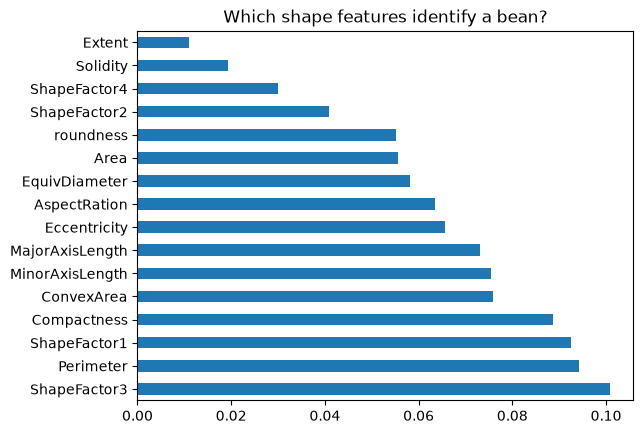

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='Which shape features identify a bean?')